In [1]:
import os
import sys
sys.path.insert(0, "./../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
#DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
exp_stiff_vals = ['000','049','099']

In [45]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
stoch_filenames_umap = [f for f in filenames if any([x in str(f) for x in exp_stiff_vals])]
stoch_filenames_umap = [stoch_filenames_umap[0], stoch_filenames_umap[3], stoch_filenames_umap[1], stoch_filenames_umap[4], stoch_filenames_umap[2], stoch_filenames_umap[5]]

stoch_filenames_umap

['C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv']

In [46]:
ode_filenames_umap = [Path(str(f).replace('stoch_sim','ODE_sim')) for f in stoch_filenames_umap]
# ode_filenames_umap = [ode_filenames_umap[0], ode_filenames_umap[3], ode_filenames_umap[1], ode_filenames_umap[4], ode_filenames_umap[2], ode_filenames_umap[5]]
ode_filenames_umap

[WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv')]

In [47]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'stoch_sim*cycdi_0_4.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)

filenames_cycdi = [filenames[2], filenames[3], filenames[0],
                 filenames[1], filenames[4], filenames[5]]
filenames_cycdi

['C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_erl_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_erl_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_cycdi_0_4.csv']

In [48]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'ode_sim*cycdi_0_4.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)

filenames_ode_cycdi = [filenames[2], filenames[3], filenames[0],
                 filenames[1], filenames[4], filenames[5]]
filenames_ode_cycdi

['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_cycdi_0_4.csv']

In [49]:
stoch_filenames_wcdk4i = stoch_filenames_umap
stoch_filenames_wcdk4i.extend(filenames_cycdi[4:])

In [50]:
stoch_filenames_wcdk4i

['C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_049_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_DMSO_stiff_099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\orig_sims\\stoch_sim_ERL_stiff_099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_cycdi_0_4.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_cycdi_0_4.csv']

In [51]:
ode_filenames_wcdk4i = ode_filenames_umap
ode_filenames_wcdk4i.extend([Path(file) for file in filenames_ode_cycdi[4:]])

In [52]:
ode_filenames_wcdk4i

[WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_000_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_049_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_DMSO_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/orig_sims/ODE_sim_ERL_stiff_099_orig.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_4.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_4.csv')]

In [53]:
# Important params to set the window size and step time distance
init_dt = 0.1                 # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

# set the random state for reproducibility; set to None to get different results each time
RANDOM_STATE = 5

In [54]:
sys_type = sys.platform
if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240502'
    r_dbpath = 'https://www.dropbox.com/scl/fi/ovk8v5fc9rvsbm43zww8h/reducer_20240502_0.1_0.1_4_0.5.sav?rlkey=jb9om518rtjth0q9bs6mdjj79&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '03_20'
    r_dbpath = 'https://www.dropbox.com/scl/fi/jlfya4m3bhp9akr3hzco2/reducer_03_20_0.1_0.1_4_0.5.sav?rlkey=3z8ozy95khsjdqplkg8ce11md&dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

r_name = f'reducer_{sys_name}_{init_dt}_{dt}_{window}_{time_step}.sav'

In [55]:
r_path = Path(SAVE_DIR,'UMAP',r_name.replace(f'{sys_name}',r_path_date))
%env R_PATH = {r_path}

env: R_PATH=C:\Users\olesk\ECM_mod_output\dist_runs\UMAP\reducer_03_20_0.1_0.1_4_0.5.sav


In [56]:
def load_sim_output(filenames: list) -> pd.DataFrame:
    sim_data = pd.DataFrame()
    for i, f in enumerate(filenames):
        tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        tmp = tmp.drop(columns=['cdh1_inact'])
        if i == 0:
            sim_data = tmp
        else:
            sim_data = pd.concat([sim_data,tmp], ignore_index=True)
    return sim_data

def calc_minmax(filenames):
    dat = load_sim_output(filenames)
    min_prots = dat.min(axis=0).to_list()
    max_prots = dat.max(axis=0).tolist()
    return max_prots, min_prots

In [57]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames, filenames_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames, filenames_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [58]:
# max_prots, min_prots = calc_minmax(stoch_filenames, ode_filenames)
max_prots, min_prots = calc_minmax(stoch_filenames_wcdk4i + ode_filenames_wcdk4i)

In [59]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [60]:
[all_prot, all_prot_ode, all_time, all_time_at] = load_norm_data(stoch_filenames_wcdk4i, ode_filenames_wcdk4i, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [62]:
all_prot.shape

(319944, 720)

In [63]:
print(f'Generating UMAP with {neighbs} neighbors and {min_d} min_dist')
reducer = umap.UMAP(
                    n_neighbors=neighbs,
                    min_dist=min_d,
                    n_components=2,
                    metric='euclidean',
                    random_state=RANDOM_STATE,
                    low_memory=True        
                    ).fit(all_prot)

Generating UMAP with 50 neighbors and 0.01 min_dist


In [64]:
embedding_all_prot = reducer.transform(all_prot)

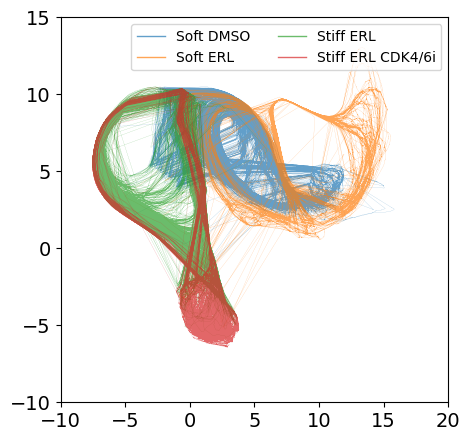

In [90]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(stoch_filenames_wcdk4i))
trk_len_ode = int(len(embedding_all_prot)/len(stoch_filenames_wcdk4i))

pos = 0

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, label="Soft DMSO")

pos = 1

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, label="Soft ERL")

pos = 5

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, label="Stiff ERL")

pos = 7

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7, label="Stiff ERL CDK4/6i")

plt.xlim(-10,20)
plt.ylim(-10, 15)

leg = plt.legend(loc="upper right", ncol=2)

for line in leg.get_lines():
    line.set_linewidth(1.0)


(-10.0, 15.0)

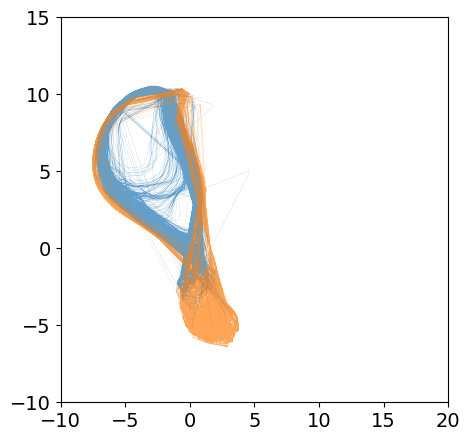

In [82]:
# Check how the UMAP projection looks
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(stoch_filenames_wcdk4i))
trk_len_ode = int(len(embedding_all_prot)/len(stoch_filenames_wcdk4i))

pos = 6

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7)

pos = 7

plt.plot(embedding_all_prot[pos*trk_len:(pos+1)*trk_len,0], embedding_all_prot[pos*trk_len:(pos+1)*trk_len,1], 
         lw=0.1, alpha=0.7)

plt.xlim(-10,20)
plt.ylim(-10, 15)
